# Customer Churn Analysis and Prediction Using Python

## Introduction

Customer churn is a major challenge in the telecommunications industry. It refers to customers discontinuing a company's services and switching to another provider.

This project focuses on analysing customer churn patterns and predicting customers who are likely to leave the company using Python and Machine Learning techniques.

Exploratory Data Analysis (EDA) is performed to understand customer behaviour, service usage, complaints, tariff plans, and other factors associated with churn. Various data visualisations are used to identify important patterns and trends.

Additionally, six Machine Learning algorithms are implemented and evaluated to predict customer churn. The models are compared using different performance metrics to identify the best-performing model.

## Objectives

- Analyse customer churn patterns using Python.
- Identify factors associated with customer churn.
- Explore customer service usage and behaviour.
- Visualise important patterns and trends.
- Apply Machine Learning algorithms to predict customer churn.
- Evaluate and compare different Machine Learning models.
- Identify the best-performing model for churn prediction.
- Provide business recommendations to improve customer retention.

## Dataset Description

The dataset contains 3,150 customer records and 14 features related to telecom customer behaviour, service usage, and subscription details.

It includes information such as call usage, SMS frequency, customer complaints, tariff plans, customer value, and churn status.

Initially, the dataset contained 3,150 records. After removing 300 duplicate records, 2,850 unique customer records were retained for further analysis and machine learning model development.

## Tools and Libraries

- Python – Programming language
- VS Code – Development environment
- Pandas – Data manipulation
- NumPy – Numerical operations
- Matplotlib – Data visualization
- Seaborn – Statistical visualization
- Scikit-learn – Machine Learning algorithms and model evaluation
- Joblib – Saving and loading the trained model

In [81]:
!pip install pandas numpy matplotlib seaborn

You should consider upgrading via the 'C:\Users\juman\AppData\Local\Programs\Python\Python39\python.exe -m pip install --upgrade pip' command.


In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [83]:
df = pd.read_csv("Customer Churn.csv")

In [84]:
df.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [85]:
df['Churn'].value_counts()

Churn
0    2655
1     495
Name: count, dtype: int64

In [86]:
churn_percentage = (df['Churn'].value_counts(normalize=True) * 100)

print(churn_percentage)

Churn
0    84.285714
1    15.714286
Name: proportion, dtype: float64


In [87]:
df.shape

(3150, 14)

In [88]:
df.columns

Index(['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount',
       'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age',
       'Customer Value', 'Churn'],
      dtype='object')

## 1. Data Exploration

In [89]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)

In [90]:
df.duplicated().sum()

np.int64(300)

## 2. Data Cleaning

In [91]:
df = df.drop_duplicates()

In [92]:
df.shape

(2850, 14)

In [93]:
df.duplicated().sum()

np.int64(0)

In [94]:
df.dtypes

Call  Failure                int64
Complains                    int64
Subscription  Length         int64
Charge  Amount               int64
Seconds of Use               int64
Frequency of use             int64
Frequency of SMS             int64
Distinct Called Numbers      int64
Age Group                    int64
Tariff Plan                  int64
Status                       int64
Age                          int64
Customer Value             float64
Churn                        int64
dtype: object

### Categorical Data Analysis

In [95]:
for col in ['Complains', 'Tariff Plan', 'Status', 'Churn']:
    print(col)
    print(df[col].value_counts())
    print("----------------")

Complains
Complains
0    2620
1     230
Name: count, dtype: int64
----------------
Tariff Plan
Tariff Plan
1    2621
2     229
Name: count, dtype: int64
----------------
Status
Status
1    2166
2     684
Name: count, dtype: int64
----------------
Churn
Churn
0    2404
1     446
Name: count, dtype: int64
----------------


### Statistical Summary

In [96]:
df.describe()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000
mean,7.802456,0.080702,32.452982,0.974737,4534.243158,70.484912,73.789825,23.870526,2.835088,1.080351,1.240000,31.077193,474.990367,0.156491
std,7.326172,0.272424,8.723075,1.550618,4199.712303,57.401512,112.062397,17.193929,0.893503,0.271883,0.427158,8.861934,514.442198,0.363384
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,29.000000,0.000000,1458.750000,28.000000,7.000000,11.000000,2.000000,1.000000,1.000000,25.000000,117.527500,0.000000
50%,6.000000,0.000000,35.000000,0.000000,3041.000000,54.500000,22.000000,21.000000,3.000000,1.000000,1.000000,30.000000,232.520000,0.000000
75%,12.000000,0.000000,38.000000,2.000000,6500.000000,96.000000,88.000000,34.000000,3.000000,1.000000,1.000000,30.000000,790.080000,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


## 3. Customer Demographic Analysis

In [97]:
df['Age'].value_counts().sort_index()

Age
15     112
25     921
30    1296
45     367
55     154
Name: count, dtype: int64

In [98]:
df.groupby('Age')['Churn'].value_counts().unstack(fill_value=0)

Churn,0,1
Age,,
15,112,0
25,764,157
30,1083,213
45,293,74
55,152,2


In [99]:
age_churn = df.groupby('Age')['Churn'].mean() * 100

age_churn

Age
15     0.000000
25    17.046688
30    16.435185
45    20.163488
55     1.298701
Name: Churn, dtype: float64

## 4. Customer Complaints Analysis

In [100]:
df.groupby('Complains')['Churn'].value_counts().unstack(fill_value=0)

Churn,0,1
Complains,,
0,2364,256
1,40,190


In [101]:
complaint_churn = df.groupby('Complains')['Churn'].mean() * 100
complaint_churn

Complains
0     9.770992
1    82.608696
Name: Churn, dtype: float64

## 5. Customer Usage Analysis

In [102]:
df.groupby('Churn')['Call  Failure'].mean()

Churn
0    7.792013
1    7.858744
Name: Call  Failure, dtype: float64

In [103]:
df.groupby('Churn')['Call  Failure'].median()

Churn
0    6.0
1    6.0
Name: Call  Failure, dtype: float64

In [104]:
df.groupby('Churn')['Subscription  Length'].mean()


Churn
0    32.595674
1    31.683857
Name: Subscription  Length, dtype: float64

In [105]:
df.groupby('Churn')['Seconds of Use'].mean()

Churn
0    5069.588186
1    1648.661435
Name: Seconds of Use, dtype: float64

In [106]:
df.groupby('Churn')['Frequency of SMS'].mean()


Churn
0    84.353577
1    16.849776
Name: Frequency of SMS, dtype: float64

## 6. Factors Associated with Customer Churn

In [107]:
df.groupby('Age Group')['Churn'].mean() * 100

Age Group
1     0.000000
2    17.046688
3    16.435185
4    20.163488
5     1.298701
Name: Churn, dtype: float64

In [108]:
df.groupby('Churn')['Customer Value'].mean()

Churn
0    538.590759
1    132.175695
Name: Customer Value, dtype: float64

In [109]:
df.groupby('Tariff Plan')['Churn'].mean() * 100

Tariff Plan
1    16.787486
2     2.620087
Name: Churn, dtype: float64

In [110]:
df.groupby('Status')['Churn'].mean() * 100

Status
1     5.586334
2    47.514620
Name: Churn, dtype: float64

## 7. Overall Customer Churn Analysis

In [111]:
df['Churn'].value_counts()

Churn
0    2404
1     446
Name: count, dtype: int64

In [112]:
churn_percentage = df['Churn'].value_counts(normalize=True) * 100
churn_percentage

Churn
0    84.350877
1    15.649123
Name: proportion, dtype: float64

## 8. Data Visualization

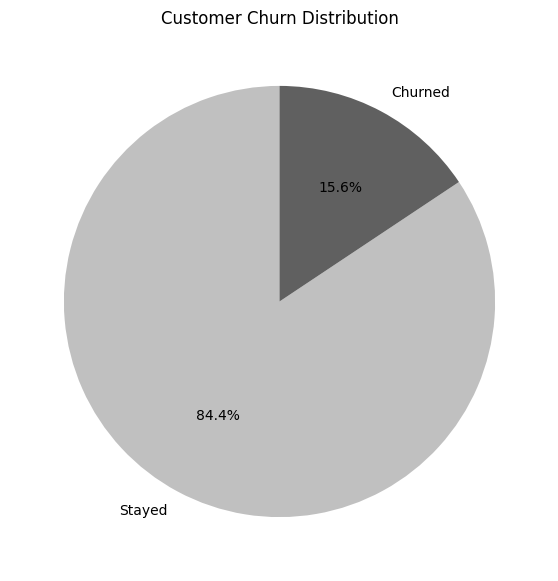

In [113]:
churn_percentage = df['Churn'].value_counts(normalize=True) * 100

plt.figure(figsize=(7, 7))

plt.pie(
    churn_percentage,
    labels=['Stayed', 'Churned'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#C0C0C0', '#606060'],
    textprops={'color': 'Black'}
)

plt.title('Customer Churn Distribution', color='Black')
plt.show()

## 9. Tariff Plan and Customer Complaints

In [114]:
df.groupby('Tariff Plan')['Complains'].sum()

Tariff Plan
1    211
2     19
Name: Complains, dtype: int64

In [115]:
df.groupby('Tariff Plan')['Complains'].mean() * 100

Tariff Plan
1    8.050362
2    8.296943
Name: Complains, dtype: float64

## 10. Correlation Analysis

In [116]:
df[['Seconds of Use', 'Frequency of SMS']].corr()

,Seconds of Use,Frequency of SMS
Seconds of Use,1.000000,0.093073
Frequency of SMS,0.093073,1.000000


### Customer Value Distribution

In [117]:
df['Customer Value'].describe()

count    2850.000000
mean      474.990367
std       514.442198
min         0.000000
25%       117.527500
50%       232.520000
75%       790.080000
max      2165.280000
Name: Customer Value, dtype: float64

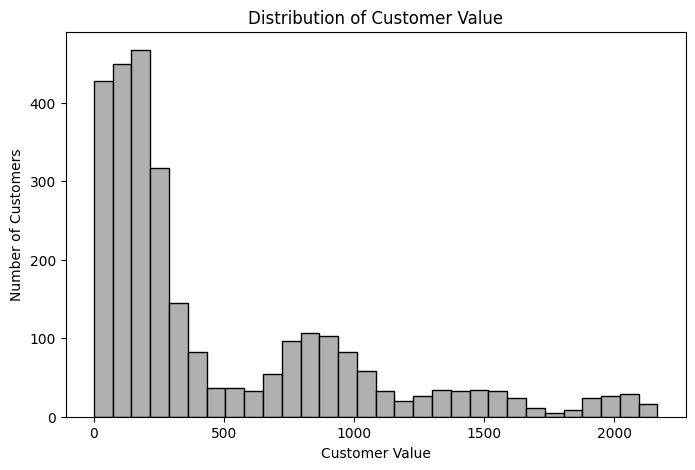

In [118]:
plt.figure(figsize=(8, 5))

plt.hist(df['Customer Value'], bins=30, color='#B0B0B0', edgecolor='black')

plt.title('Distribution of Customer Value')
plt.xlabel('Customer Value')
plt.ylabel('Number of Customers')

plt.show()

In [119]:
df[['Seconds of Use', 'Customer Value']].corr()

,Seconds of Use,Customer Value
Seconds of Use,1.000000,0.408536
Customer Value,0.408536,1.000000


In [120]:
df[['Frequency of SMS', 'Customer Value']].corr()

,Frequency of SMS,Customer Value
Frequency of SMS,1.000000,0.922852
Customer Value,0.922852,1.000000


In [121]:
df[['Frequency of use', 'Customer Value']].corr()

,Frequency of use,Customer Value
Frequency of use,1.000000,0.394647
Customer Value,0.394647,1.000000


### Scatter Plot: Call Usage vs Customer Value

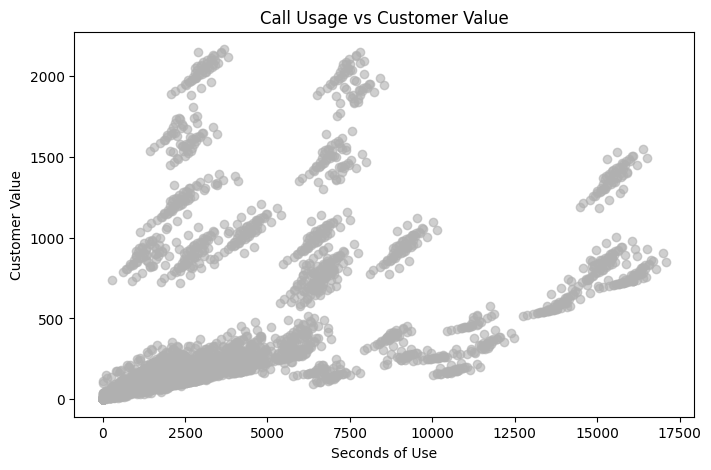

In [122]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Seconds of Use'], df['Customer Value'],color='#B0B0B0', alpha=0.6)

plt.title('Call Usage vs Customer Value')
plt.xlabel('Seconds of Use')
plt.ylabel('Customer Value')

plt.show()

### Scatter Plot: SMS Usage vs Customer Value

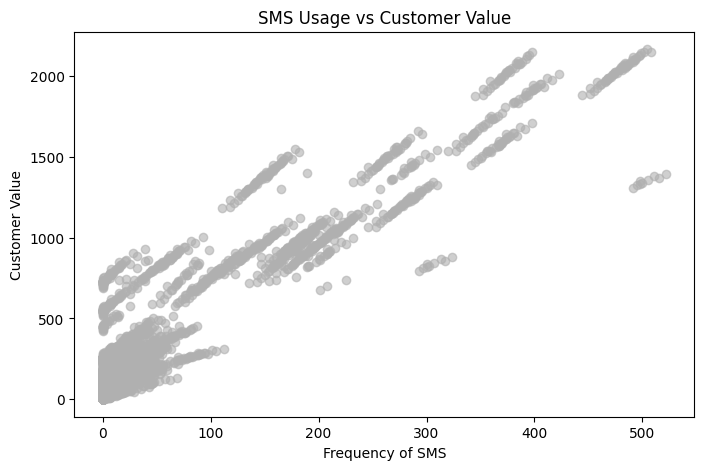

In [123]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Frequency of SMS'], df['Customer Value'],color='#B0B0B0', alpha=0.6)

plt.title('SMS Usage vs Customer Value')
plt.xlabel('Frequency of SMS')
plt.ylabel('Customer Value')

plt.show()

### Scatter Plot: Frequency of Use vs Customer Value

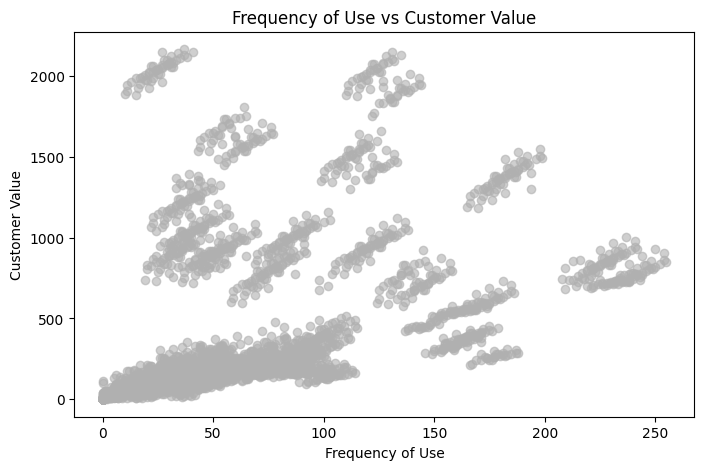

In [124]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Frequency of use'], df['Customer Value'],color='#B0B0B0', alpha=0.6)

plt.title('Frequency of Use vs Customer Value')
plt.xlabel('Frequency of Use')
plt.ylabel('Customer Value')

plt.show()

### Correlation Heatmap

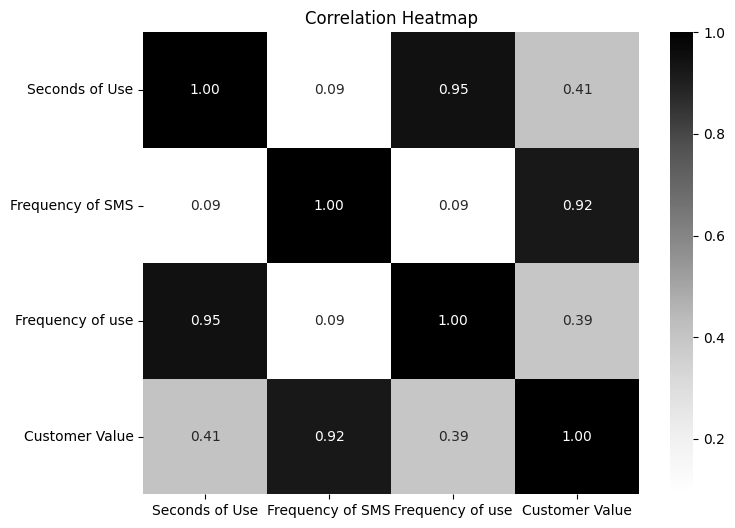

In [125]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[['Seconds of Use', 'Frequency of SMS',
        'Frequency of use', 'Customer Value']].corr(),
    annot=True,
    cmap='Greys',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

### Bar Chart: Customer Churn Rate by Complaints

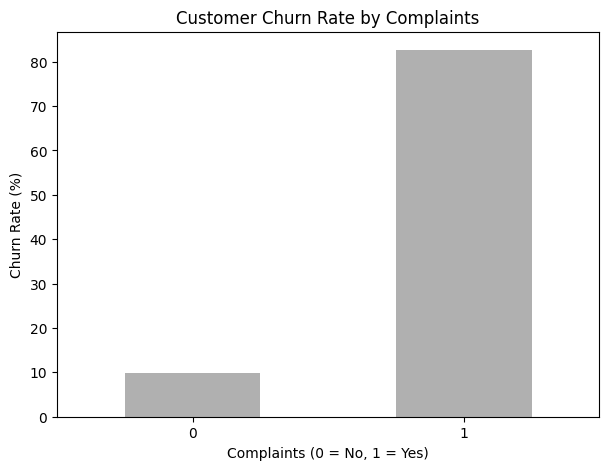

In [126]:
complaint_churn = df.groupby('Complains')['Churn'].mean() * 100

plt.figure(figsize=(7, 5))

complaint_churn.plot(kind='bar', color='#B0B0B0')

plt.title('Customer Churn Rate by Complaints')
plt.xlabel('Complaints (0 = No, 1 = Yes)')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=0)
plt.show()

### Bar Chart: Customer Churn Rate by Age Group

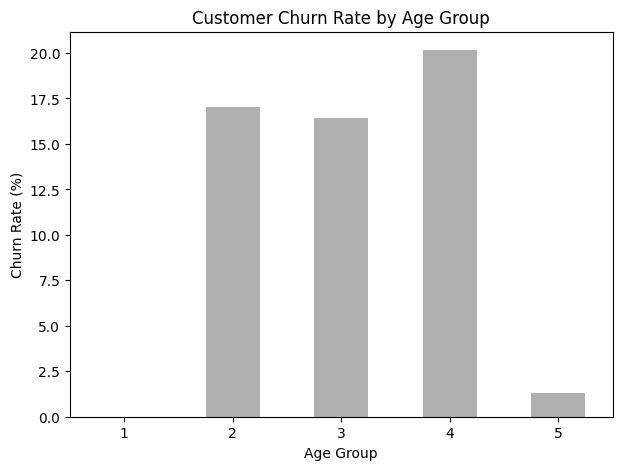

In [127]:
age_churn = df.groupby('Age Group')['Churn'].mean() * 100

plt.figure(figsize=(7, 5))

age_churn.plot(kind='bar', color='#B0B0B0')

plt.title('Customer Churn Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=0)
plt.show()

### Bar Chart: Customer Churn Rate by Tariff Plan

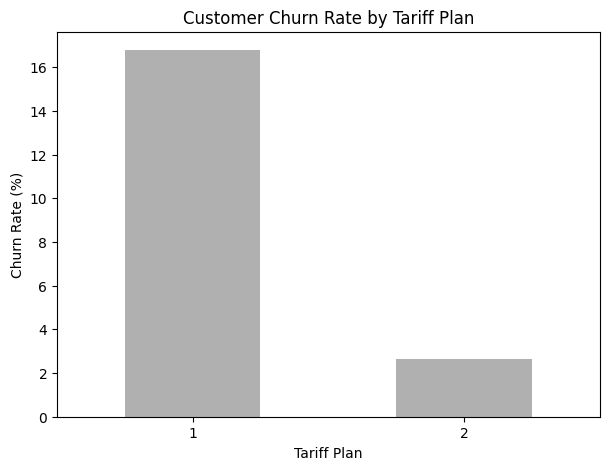

In [128]:
tariff_churn = df.groupby('Tariff Plan')['Churn'].mean() * 100

plt.figure(figsize=(7, 5))

tariff_churn.plot(kind='bar', color='#B0B0B0')

plt.title('Customer Churn Rate by Tariff Plan')
plt.xlabel('Tariff Plan')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=0)
plt.show()

### Bar Chart: Customer Churn Rate by Status

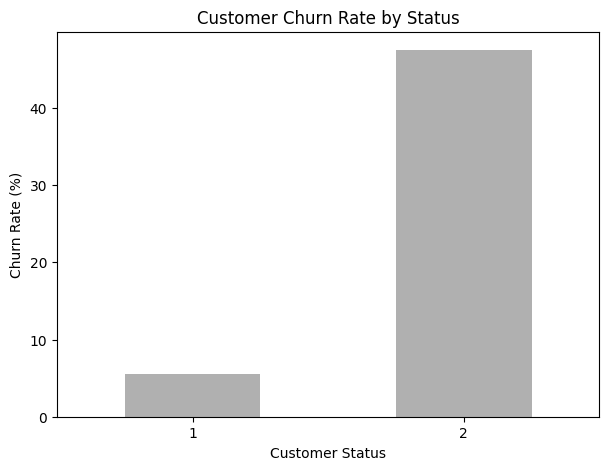

In [129]:
status_churn = df.groupby('Status')['Churn'].mean() * 100

plt.figure(figsize=(7, 5))

status_churn.plot(kind='bar', color='#B0B0B0')

plt.title('Customer Churn Rate by Status')
plt.xlabel('Customer Status')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=0)
plt.show()

### Bar Chart: Average Customer Value by Churn Status

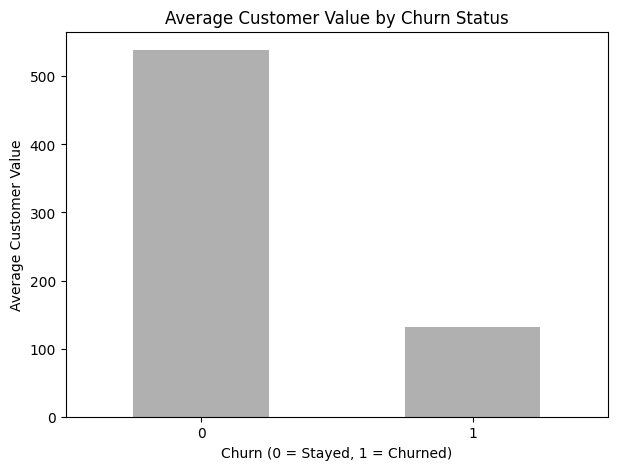

In [130]:
customer_value_churn = df.groupby('Churn')['Customer Value'].mean()

plt.figure(figsize=(7, 5))

customer_value_churn.plot(kind='bar', color='#B0B0B0')

plt.title('Average Customer Value by Churn Status')
plt.xlabel('Churn (0 = Stayed, 1 = Churned)')
plt.ylabel('Average Customer Value')

plt.xticks(rotation=0)
plt.show()

### Bar Chart: Average Call Usage by Churn Status

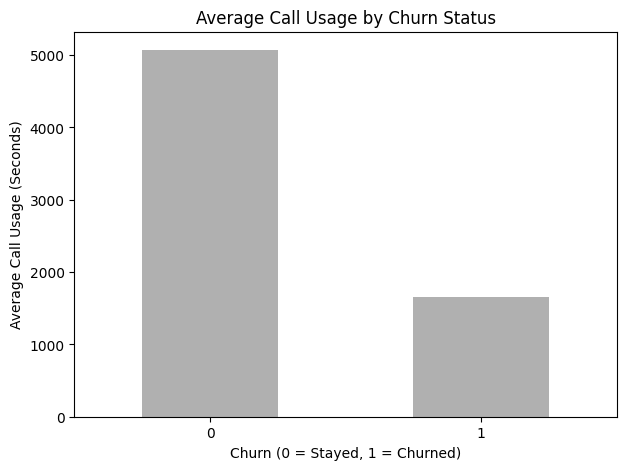

In [131]:
call_usage_churn = df.groupby('Churn')['Seconds of Use'].mean()

plt.figure(figsize=(7, 5))

call_usage_churn.plot(kind='bar', color='#B0B0B0')

plt.title('Average Call Usage by Churn Status')
plt.xlabel('Churn (0 = Stayed, 1 = Churned)')
plt.ylabel('Average Call Usage (Seconds)')

plt.xticks(rotation=0)
plt.show()

### Bar Chart: Average SMS Usage by Churn Status

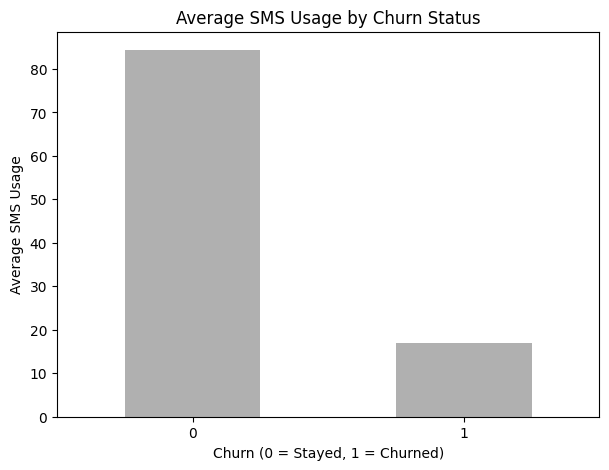

In [132]:
sms_usage_churn = df.groupby('Churn')['Frequency of SMS'].mean()

plt.figure(figsize=(7, 5))

sms_usage_churn.plot(kind='bar', color='#B0B0B0')

plt.title('Average SMS Usage by Churn Status')
plt.xlabel('Churn (0 = Stayed, 1 = Churned)')
plt.ylabel('Average SMS Usage')

plt.xticks(rotation=0)
plt.show()

### Bar Chart: Customer Complaint Rate by Tariff Plan

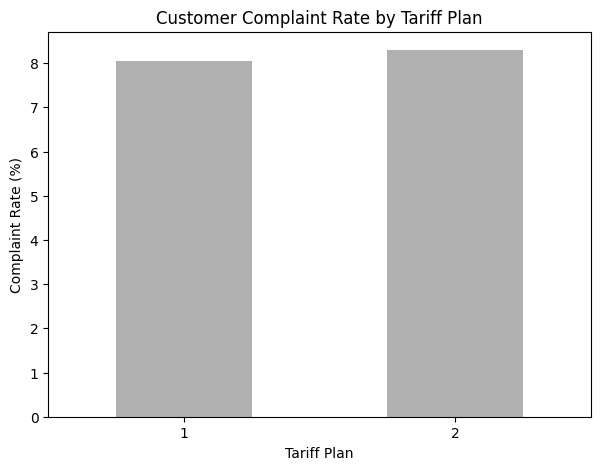

In [133]:
complaint_tariff = df.groupby('Tariff Plan')['Complains'].mean() * 100

plt.figure(figsize=(7, 5))

complaint_tariff.plot(kind='bar', color='#B0B0B0')

plt.title('Customer Complaint Rate by Tariff Plan')
plt.xlabel('Tariff Plan')
plt.ylabel('Complaint Rate (%)')

plt.xticks(rotation=0)
plt.show()

### Scatter Plot: Call Usage vs Frequency of Use

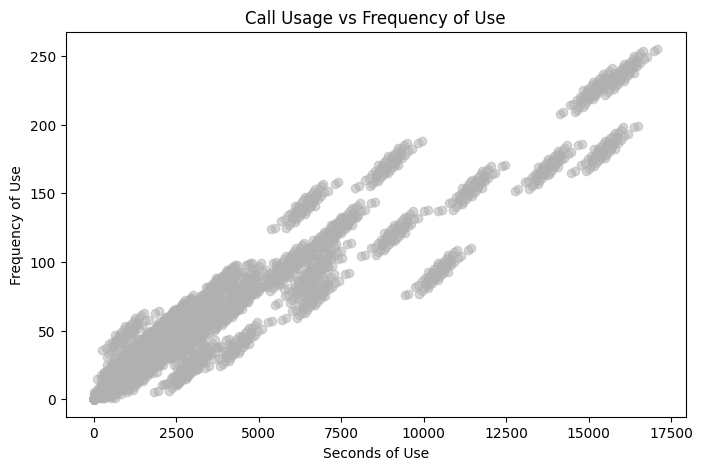

In [134]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Seconds of Use'], df['Frequency of use'], alpha=0.5, color='#B0B0B0')

plt.title('Call Usage vs Frequency of Use')
plt.xlabel('Seconds of Use')
plt.ylabel('Frequency of Use')

plt.show()

### 11. Key Findings

#### 1. Overall Customer Churn
- Out of 2,850 customers, 446 customers (15.65%) churned.
- 2,404 customers (84.35%) remained with the telecom company.

#### 2. Customer Complaints
- Customers who complained had a significantly higher churn rate (82.61%).
- Customers without complaints had a churn rate of 9.77%.

#### 3. Customer Usage Behaviour
- Churned customers had considerably lower average call usage than retained customers.
- Churned customers also had considerably lower average SMS usage.

#### 4. Customer Value
- Retained customers had an average customer value of 538.59.
- Churned customers had an average customer value of 132.18.

#### 5. Age Group Analysis
- Age 45 recorded the highest churn rate (20.16%).
- Age 30 had the highest number of churned customers.

#### 6. Tariff Plan Analysis
- Tariff Plan 1 recorded a churn rate of 16.79%.
- Tariff Plan 2 recorded a churn rate of 2.62%.

#### 7. Correlation Analysis
- Frequency of SMS showed a very strong positive correlation with Customer Value (0.92).
- Seconds of Use showed a moderate positive correlation with Customer Value (0.41).
 #### 8. Subscription Length Analysis
- Retained customers had a slightly higher average subscription length (32.60) compared to churned customers (31.68).

### 12. Business Recommendations

Based on the analysis, the following actions are recommended:

1. **Improve Complaint Handling:** Investigate customer complaints quickly and provide effective solutions to reduce churn.

2. **Monitor Customer Usage:** Identify customers with declining call and SMS usage and offer suitable retention support.

3. **Focus on High-Risk Customers:** Pay attention to customer groups with higher observed churn rates.

4. **Review Tariff Plans:** Evaluate the differences in churn rates across tariff plans and understand customer preferences.

5. **Improve Customer Engagement:** Develop loyalty programmes and personalised offers to encourage customers to remain with the company.

6. **Retain High-Value Customers:** Identify valuable customers and provide services that improve their satisfaction and loyalty.

## 14. Machine Learning Model Development

In [135]:
X = df.drop('Churn', axis=1)
y = df['Churn']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2850, 13)
Target shape: (2850,)


In [136]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (2280, 13)
Testing data: (570, 13)


### 15. Logistic Regression

Logistic Regression is a supervised machine learning algorithm used for classification.

In this project, Logistic Regression is used to predict whether a telecom customer will stay or leave the company.

In [137]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create Logistic Regression model
log_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])
log_model.fit(X_train, y_train)
y_pred = log_model.predict(X_test)
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Logistic Regression Accuracy: 0.9035087719298246
              precision    recall  f1-score   support

           0       0.91      0.98      0.94       481
           1       0.83      0.48      0.61        89

    accuracy                           0.90       570
   macro avg       0.87      0.73      0.78       570
weighted avg       0.90      0.90      0.89       570



#### Confusion Matrix – Logistic Regression

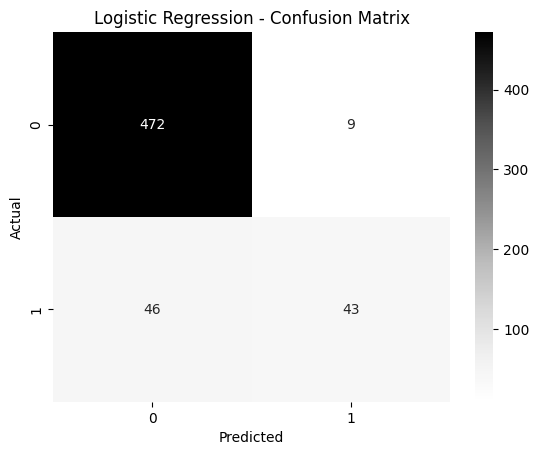

In [138]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Greys')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

#### Logistic Regression – Model Evaluation

- Accuracy: 90.35%
- Precision (Churn): 83%
- Recall (Churn): 48%
- F1-score (Churn): 61%

The model achieved 90.35% accuracy. However, its recall for churn customers is relatively low, indicating that some customers who are likely to leave are not identified correctly.

### 16. K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) is a supervised machine learning algorithm used for classification.

It predicts the class of a new customer by comparing it with the nearest customers in the training dataset.

In this project, KNN is used to predict whether a telecom customer will stay or leave the company.

In [139]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=5))
])
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)
print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

KNN Accuracy: 0.9473684210526315
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       481
           1       0.83      0.83      0.83        89

    accuracy                           0.95       570
   macro avg       0.90      0.90      0.90       570
weighted avg       0.95      0.95      0.95       570



#### Confusion Matrix – KNN

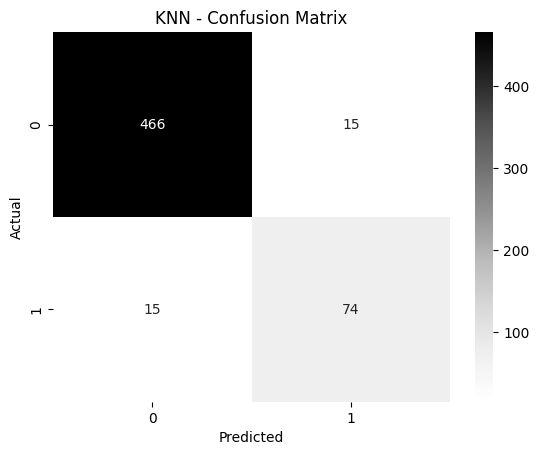

In [140]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_knn = confusion_matrix(y_test, y_pred_knn)

sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greys')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('KNN - Confusion Matrix')
plt.show()

#### KNN – Model Evaluation

- Accuracy: 94.74%
- Precision (Churn): 83%
- Recall (Churn): 83%
- F1-score (Churn): 83%

The KNN model achieved 94.74% accuracy. It also showed better recall for churn customers compared to Logistic Regression, identifying a higher proportion of customers who are likely to leave the company.

### 17. Decision Tree Classifier

Decision Tree is a supervised machine learning algorithm used for classification.

It makes predictions by splitting the data into branches based on different feature conditions.

In this project, Decision Tree is used to predict whether a telecom customer will stay or leave the company.

In [141]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.9122807017543859
              precision    recall  f1-score   support

           0       0.93      0.97      0.95       481
           1       0.80      0.58      0.68        89

    accuracy                           0.91       570
   macro avg       0.86      0.78      0.81       570
weighted avg       0.91      0.91      0.91       570



#### Confusion Matrix – Decision Tree


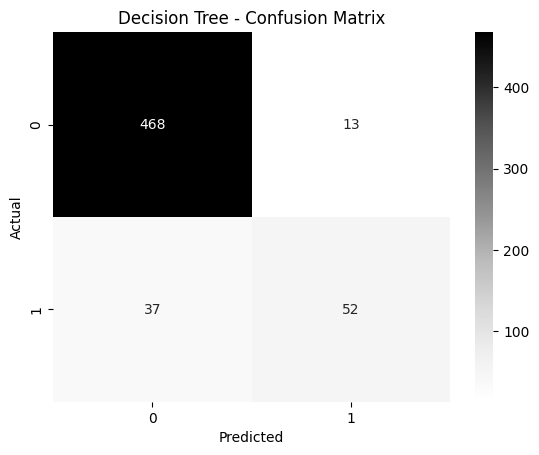

In [142]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_dt = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greys')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree - Confusion Matrix')
plt.show()

#### Decision Tree – Model Evaluation

- Accuracy: 91.23%
- Precision (Churn): 80%
- Recall (Churn): 58%
- F1-score (Churn): 68%

The Decision Tree model achieved 91.23% accuracy. However, its recall for churn customers is 58%, indicating that some customers who are likely to leave are not identified correctly.

### 18. Random Forest Classifier

Random Forest is a supervised machine learning algorithm used for classification.

It combines multiple decision trees to make predictions. The final prediction is based on the majority vote of the trees.

In this project, Random Forest is used to predict whether a telecom customer will stay or leave the company.

In [143]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.9614035087719298
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       481
           1       0.94      0.81      0.87        89

    accuracy                           0.96       570
   macro avg       0.95      0.90      0.92       570
weighted avg       0.96      0.96      0.96       570



#### Confusion Matrix – Random Forest

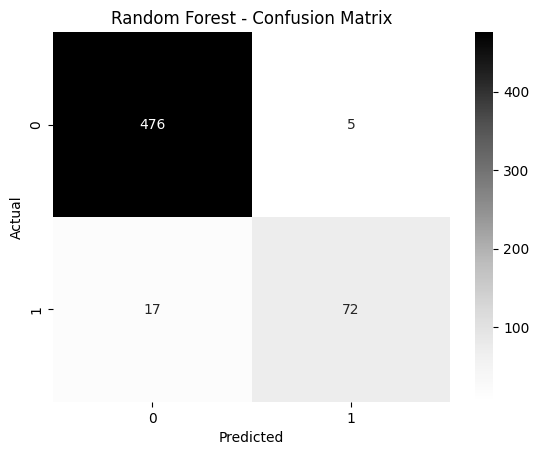

In [144]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greys')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest - Confusion Matrix')
plt.show()

#### Random Forest – Model Evaluation

- Accuracy: 96.14%
- Precision (Churn): 94%
- Recall (Churn): 81%
- F1-score (Churn): 87%

The Random Forest model achieved 96.14% accuracy. It showed strong performance in identifying churn customers, with 94% precision and 81% recall.

### 19. Support Vector Machine (SVM)

Support Vector Machine is a supervised machine learning algorithm used for classification.

It finds the best decision boundary (hyperplane) to separate different classes in the dataset.

In this project, SVM is used to predict whether a telecom customer will stay or leave the company.

In [145]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC())
])

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

           0       0.93      0.99      0.96       481
           1       0.93      0.62      0.74        89

    accuracy                           0.93       570
   macro avg       0.93      0.80      0.85       570
weighted avg       0.93      0.93      0.93       570



#### Confusion Matrix – SVM

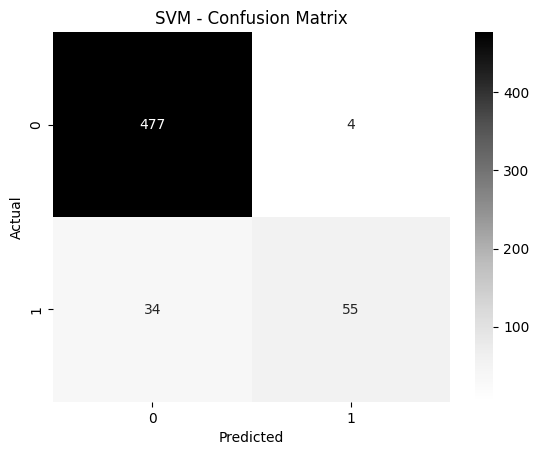

In [146]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_svm = confusion_matrix(y_test, y_pred_svm)

sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greys')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVM - Confusion Matrix')
plt.show()

#### SVM – Model Evaluation

- Accuracy: 93.33%
- Precision (Churn): 93%
- Recall (Churn): 62%
- F1-score (Churn): 74%

The SVM model achieved 93.33% accuracy. It showed high precision for churn customers, but its recall was 62%, indicating that some actual churn customers were not identified.

### 20. Naive Bayes Classifier

Naive Bayes is a supervised machine learning algorithm based on Bayes' Theorem.

It predicts the class of a customer by calculating probabilities based on the available features.

In this project, Naive Bayes is used to predict whether a telecom customer will stay or leave the company.

In [147]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))

print(classification_report(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.7105263157894737
              precision    recall  f1-score   support

           0       0.97      0.68      0.80       481
           1       0.34      0.90      0.49        89

    accuracy                           0.71       570
   macro avg       0.66      0.79      0.64       570
weighted avg       0.87      0.71      0.75       570



#### Confusion Matrix – Naive Bayes

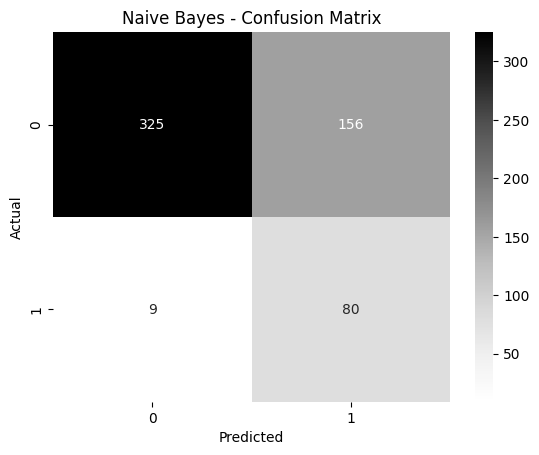

In [148]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_nb = confusion_matrix(y_test, y_pred_nb)

sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Greys')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Naive Bayes - Confusion Matrix')
plt.show()

#### Naive Bayes – Model Evaluation

- Accuracy: 71.05%
- Precision (Churn): 34%
- Recall (Churn): 90%
- F1-score (Churn): 49%

The Naive Bayes model identified 90% of actual churn customers. However, its precision was only 34%, meaning many customers predicted as churn did not actually leave the company.

### 21. Model Comparison

In this section, the performance of all six machine learning algorithms is compared using Accuracy, Precision, Recall, and F1-score.

This comparison helps identify the most suitable model for predicting telecom customer churn.

In [149]:
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN', 'Decision Tree',
              'Random Forest', 'SVM', 'Naive Bayes'],

    'Accuracy (%)': [90.35, 94.74, 91.23, 96.14, 93.33, 71.05],

    'Churn Precision (%)': [83, 83, 80, 94, 93, 34],

    'Churn Recall (%)': [48, 83, 58, 81, 62, 90],

    'Churn F1-score (%)': [61, 83, 68, 87, 74, 49]
})

model_comparison

,Model,Accuracy (%),Churn Precision (%),Churn Recall (%),Churn F1-score (%)
0,Logistic Regression,90.35,83,48,61
1,KNN,94.74,83,83,83
2,Decision Tree,91.23,80,58,68
3,Random Forest,96.14,94,81,87
4,SVM,93.33,93,62,74
5,Naive Bayes,71.05,34,90,49


### 22. Best Model Selection

Based on the model comparison, Random Forest is selected as the best overall model.

It achieved the highest accuracy of 96.14%, with 94% precision, 81% recall, and 87% F1-score for churn customers.

Although Naive Bayes achieved the highest churn recall (90%), its precision was only 34%. Random Forest provides a better balance between identifying churn customers and avoiding false predictions.

In [150]:
import joblib

joblib.dump(rf_model, 'best_churn_model.pkl')

print("Best model saved successfully!")

Best model saved successfully!


In [151]:

loaded_model = joblib.load('best_churn_model.pkl')

new_customer = X_test.iloc[[0]]

prediction = loaded_model.predict(new_customer)

if prediction[0] == 1:
    print("Prediction: Customer is likely to Churn")
else:
    print("Prediction: Customer is likely to Stay")

Prediction: Customer is likely to Churn


### 23. Feature Importance Analysis

Feature importance helps identify which customer-related factors contribute most to the Random Forest model's predictions of customer churn.

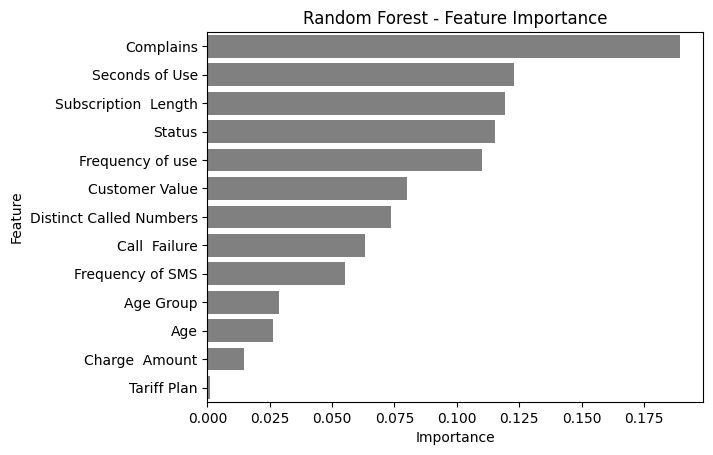

In [152]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature',
    color='grey'
)

plt.title('Random Forest - Feature Importance')
plt.show()

### 24. Final Project Conclusion

This project focused on analysing and predicting customer churn in the telecom industry using Python and Machine Learning techniques.

Exploratory Data Analysis (EDA) helped identify important patterns in customer behaviour, service usage, complaints, tariff plans, and customer value. The findings revealed that customer complaints and lower service usage were associated with a higher likelihood of churn.

Six Machine Learning algorithms were implemented and evaluated: Logistic Regression, K-Nearest Neighbors (KNN), Decision Tree, Random Forest, Support Vector Machine (SVM), and Naive Bayes.

Among these models, Random Forest achieved the best overall performance, with an accuracy of 96.14%, 94% precision, 81% recall, and an 87% F1-score for churn customers.

Feature Importance Analysis provided further insights into the factors influencing the model's predictions. The selected Random Forest model was also saved and used to predict customer churn.

Overall, this project demonstrates how data analysis and Machine Learning can help telecom companies identify customers at risk of leaving, understand customer behaviour, and make data-driven decisions to improve customer retention.